# 02 · Global explanations

What the released model relies on, across many transactions rather than one.

- **Contributions come from XGBoost's own TreeSHAP** (`fraudlens.explain`), the same
  numbers the service will store. The `shap` library is used here for plotting only.
- **Validation rows only.** A sample of the public training partition's validation
  slices; the test partition is not read.
- **Units are log-odds.** A contribution of +1 multiplies the odds of fraud by about 2.7.
- Run `python -m fraudlens.explain.checks --bundle models/<version>` first; section 4
  reads its output.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb

if not Path("data").exists():  # executed from notebooks/
    os.chdir("..")

from fraudlens.common.paths import TRAINVAL_FEATURES_PATH
from fraudlens.data.splits import assign_roles, split_bounds
from fraudlens.explain.contributions import compute_contributions
from fraudlens.explain.reason_codes import load_templates
from fraudlens.features.definitions import FEATURE_NAMES
from fraudlens.features.encoding import FEATURE_TYPES, encode_frame
from fraudlens.training.bundle import ModelBundle

plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

bundle_dir = sorted(Path("models").glob("*/manifest.json"))[-1].parent
bundle = ModelBundle.load(bundle_dir)
table = pd.read_parquet(TRAINVAL_FEATURES_PATH)
ts = table["event_ts"].to_numpy()
validation = table[np.isin(assign_roles(ts, split_bounds(ts)), ["valid_early", "valid_late"])]

rng = np.random.default_rng(0)
sample = validation.iloc[np.sort(rng.choice(len(validation), 20_000, replace=False))]
X = encode_frame(sample)
contributions = compute_contributions(bundle.booster, X, FEATURE_NAMES, FEATURE_TYPES)
frauds = int(sample["is_fraud"].sum())
print(f"bundle {bundle.version}: {len(sample):,} validation rows, {frauds} frauds")
print(f"bias (expected margin): {contributions.bias[0]:.3f} log-odds")

bundle 2026-11-17.1: 20,000 validation rows, 124 frauds
bias (expected margin): -3.320 log-odds


## 1. Global importance

Each dot is one transaction; its position is that feature's contribution to the margin and
its colour is the feature's value. The category feature is shown by its code.

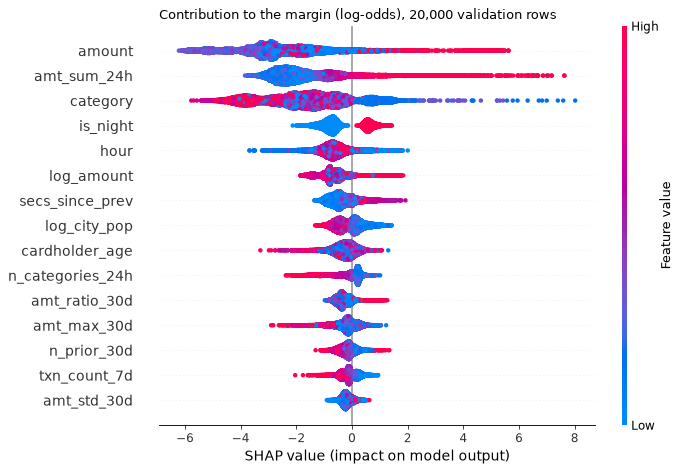

In [2]:
display_values = pd.DataFrame(X, columns=FEATURE_NAMES)
shap.summary_plot(
    contributions.values, display_values, max_display=15, show=False, plot_size=(9, 6)
)
plt.title("Contribution to the margin (log-odds), 20,000 validation rows", loc="left")
plt.tight_layout()
plt.show()

## 2. Grouped importance

The reason codes sum correlated features into groups. Mean absolute contribution per
group, for all rows and for frauds.

In [3]:
templates = load_templates()
grouped = contributions.grouped(templates.groups)
fraud = sample["is_fraud"].to_numpy() == 1
pd.DataFrame(
    {
        "group": [templates.titles[g] for g in templates.groups],
        "all rows": np.abs(grouped).mean(axis=0),
        "fraud rows": np.abs(grouped[fraud]).mean(axis=0),
    }
).set_index("group").round(3).sort_values("fraud rows", ascending=False)

,all rows,fraud rows
group,,
Amount against this card's pattern,4.410,6.112
Purchase pace on this card,2.293,4.241
Time of day and category,2.939,2.292
Cardholder context,0.691,0.656
New merchant or category,0.416,0.470
Distance and travel,0.321,0.208


## 3. How the amount ratio acts

Contribution of `amt_ratio_30d` against its value: the multiple of the card's 30-day
average. Rows with no history have no ratio and are left out.

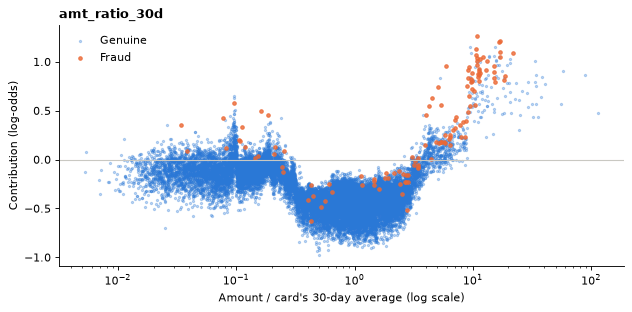

In [4]:
column = FEATURE_NAMES.index("amt_ratio_30d")
ratio = X[:, column]
known = ~np.isnan(ratio)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    ratio[known & ~fraud],
    contributions.values[known & ~fraud, column],
    s=4,
    alpha=0.3,
    color="#2a78d6",
    label="Genuine",
)
ax.scatter(
    ratio[known & fraud],
    contributions.values[known & fraud, column],
    s=10,
    alpha=0.8,
    color="#eb6834",
    label="Fraud",
)
ax.set_xscale("log")
ax.axhline(0, color="#c9c8c2", linewidth=1)
ax.set_xlabel("Amount / card's 30-day average (log scale)")
ax.set_ylabel("Contribution (log-odds)")
ax.set_title("amt_ratio_30d", loc="left", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Strongest interactions

SHAP interaction values on 2,000 rows: the mean absolute value of each pair's
interaction, largest first. A strong pair means the model reads the two features jointly.

In [5]:
few = X[:2_000]
matrix = xgb.DMatrix(
    few,
    feature_names=list(FEATURE_NAMES),
    feature_types=list(FEATURE_TYPES),
    enable_categorical=True,
)
interactions = bundle.booster.predict(matrix, pred_interactions=True)[:, :-1, :-1]
strength = np.abs(interactions).mean(axis=0)
pairs = [
    (FEATURE_NAMES[i], FEATURE_NAMES[j], 2 * strength[i, j])
    for i in range(len(FEATURE_NAMES))
    for j in range(i + 1, len(FEATURE_NAMES))
]
pd.DataFrame(
    sorted(pairs, key=lambda p: -p[2])[:10], columns=["feature", "with", "mean |interaction|"]
).round(4)

,feature,with,mean |interaction|
0,amount,category,1.3029
1,hour,cardholder_age,0.4779
2,category,cardholder_age,0.4052
3,log_amount,category,0.3977
4,amt_max_30d,amt_sum_24h,0.3583
5,category,hour,0.3018
6,hour,secs_since_prev,0.2709
7,amount,hour,0.1974
8,category,amt_sum_24h,0.1906
9,amt_sum_24h,n_categories_24h,0.1824


## 5. Checks and explanation drift

From `docs/results/explainability.json`: additivity on 10,000 rows, the stability of the
top three reason groups when the amount moves by 1%, and the monthly mean absolute
contribution of the leading features, for all rows and for frauds.

additivity: {'max_abs_error': 2.5477958843111992e-05, 'passed': True, 'rows': 10000, 'tolerance': 0.0001}
stability: {'amount_change': 0.01, 'rows': 1000, 'share_unchanged': 0.978, 'top_groups_compared': 3}
top features: ['amount', 'amt_sum_24h', 'category', 'is_night', 'hour', 'log_amount', 'secs_since_prev', 'log_city_pop']


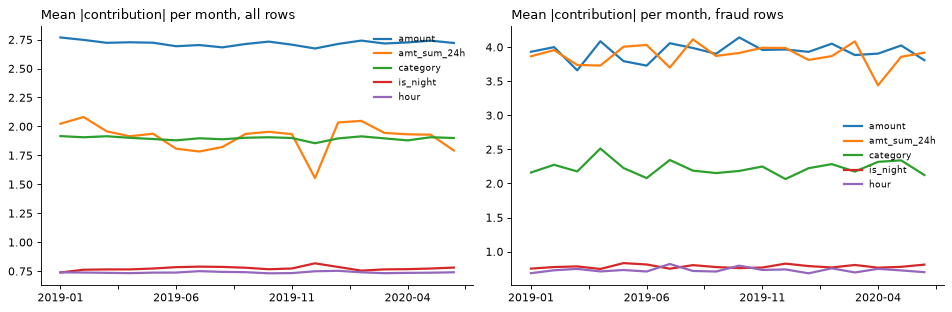

,amount,amt_sum_24h,category,is_night,hour
coefficient of variation across months,,,,,
all,0.009,0.065,0.008,0.022,0.008
fraud,0.032,0.042,0.049,0.033,0.049


In [6]:
checks = json.loads(Path("docs/results/explainability.json").read_text())
print("additivity:", checks["additivity"])
print("stability:", checks["stability"])
print("top features:", [r["feature"] for r in checks["global_ranking"][:8]])

drift = pd.DataFrame(checks["monthly_attribution"])
leaders = [r["feature"] for r in checks["global_ranking"][:5]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, population in zip(axes, ("all", "fraud"), strict=True):
    part = drift[drift["population"] == population].set_index("month")[leaders]
    part.plot(ax=ax, linewidth=2)
    ax.set_title(f"Mean |contribution| per month, {population} rows", loc="left")
    ax.set_xlabel("")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

spread = drift.groupby("population")[leaders].agg(lambda s: s.std() / s.mean())
spread.round(3).rename_axis("coefficient of variation across months")

## Reading the results

- The ranking matches the exploratory analysis: amount and the card's 24-hour spend lead,
  followed by category and night-time. No identifier-like feature appears, which is the
  leakage smell this notebook checks for.
- Contributions are in log-odds, so a reason's share of the upward push is the honest
  unit for the console, not a percentage of probability.
- The drift table compares months. For four of the five leading features, fraud-row
  attributions vary more from month to month than all-traffic attributions; the card's
  24-hour spend is the exception. That is why both populations are monitored.